# Unit-root testing: EUR/USD levels and changes

This analysis compares monthly EUR/USD exchange-rate levels with log changes.
Time-series plots and augmented Dickey-Fuller (ADF) tests assess evidence
against a unit root, distinguishing it from the broader conditions for
weak stationarity.

The analysis uses **192 monthly observations for January 2010–December 2025**.
Levels are quoted in **US dollars per euro**; log changes are expressed
in **percent**.

Data Sources:

- [Federal Reserve Board, H.10 historical euro rates](https://www.federalreserve.gov/releases/h10/hist/dat00_eu.htm):
  daily New York noon buying rates in US dollars per euro, not seasonally adjusted.
  Each month's level is its last available quotation.
- [FRED DEXUSEU](https://fred.stlouisfed.org/series/DEXUSEU): equivalent series and definition.


## Environment setup

**Colab:** the setup expects the complete `Notebooks` folder in **My Drive**,
with its subfolders and CSV files. Running the cell below mounts Google Drive
and requests access.
**Local Jupyter:** the same folder structure supports local execution.
`NOTEBOOKS_ROOT` specifies a different location when needed.


In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "Time_Series"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: Time_Series


## Libraries

In [2]:
from inspect import signature
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from IPython.display import display

## Data

In [3]:
levels = pd.read_csv(DATA_DIR / "monthly_eur_usd.csv", index_col="date", parse_dates=True)
months = levels.index.to_period("M")
expected = pd.period_range("2009-12", "2025-12", freq="M")
if not months.equals(expected) or levels.isna().any().any():
    raise ValueError("Inspect missing, duplicate or unordered monthly observations.")
if not levels["usd_per_eur"].gt(0).all():
    raise ValueError("Inspect non-positive exchange-rate quotations.")
display(levels.head().round(4))

,usd_per_eur,observation_date
date,,
2009-12-31,1.4332,2009-12-31
2010-01-31,1.3870,2010-01-29
2010-02-28,1.3660,2010-02-26
2010-03-31,1.3526,2010-03-31
2010-04-30,1.3302,2010-04-30


## Exchange-rate levels and log changes

With $S_t$ denoting the last published USD-per-EUR quotation in month $t$, the monthly log change is

$$r_t=100\log(S_t/S_{t-1}).$$

A positive change means euro appreciation against the dollar. This is a change
in the exchange-rate quotation, not the total return of a currency investment:
interest earned or funding costs are not included.

Dates label calendar month ends; `observation_date` retains the actual last
available quotation date. This is an end-of-month series, not a monthly average.
No missing month is interpolated. December 2009 is a base only; all plots and
tests below use January 2010-December 2025.

In [4]:
data = levels.copy()
data["log_change_pct"] = 100 * np.log(data["usd_per_eur"]).diff()
data = data.iloc[1:].copy()
if data.isna().any().any():
    raise ValueError("Missing analysis observations: inspect the data.")
exchange_rate = data["usd_per_eur"]
changes = data["log_change_pct"]
print(f"Analysis sample: {len(data)} months, {data.index[0]:%Y-%m} to {data.index[-1]:%Y-%m}")
display(data[["usd_per_eur", "observation_date", "log_change_pct"]].head().round(4))

Analysis sample: 192 months, 2010-01 to 2025-12


,usd_per_eur,observation_date,log_change_pct
date,,,
2010-01-31,1.3870,2010-01-29,-3.2767
2010-02-28,1.3660,2010-02-26,-1.5256
2010-03-31,1.3526,2010-03-31,-0.9858
2010-04-30,1.3302,2010-04-30,-1.6699
2010-05-31,1.2369,2010-05-28,-7.2721


## Levels and changes through time

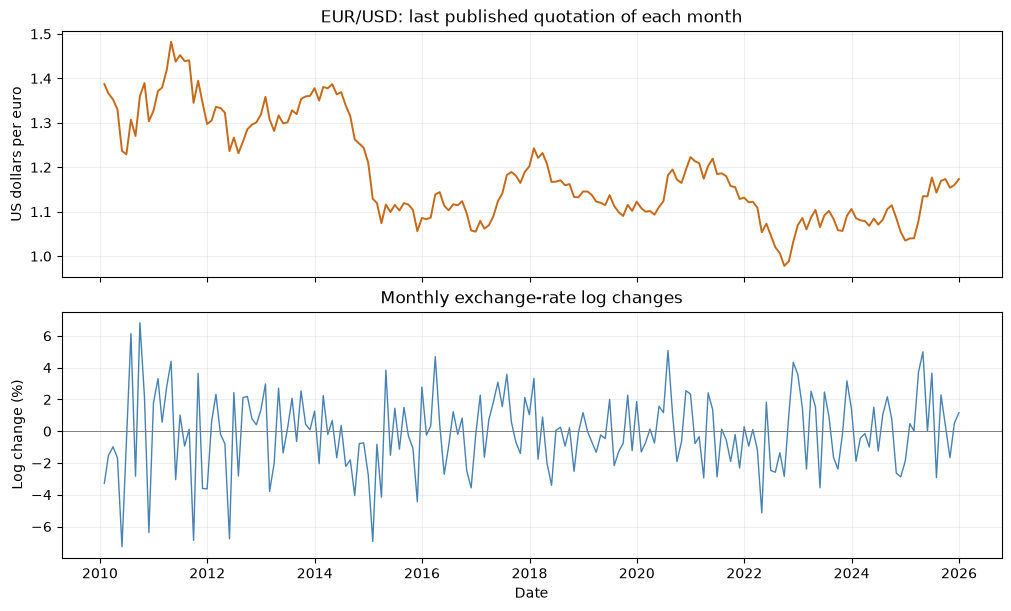

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, constrained_layout=True)
axes[0].plot(exchange_rate.index, exchange_rate, color="#C66A19", linewidth=1.4)
axes[0].set(title="EUR/USD: last published quotation of each month", ylabel="US dollars per euro")
axes[1].plot(changes.index, changes, color="steelblue", linewidth=1)
axes[1].axhline(0, color="grey", linewidth=0.7)
axes[1].set(title="Monthly exchange-rate log changes", ylabel="Log change (%)", xlabel="Date")
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

The exchange-rate level makes persistent movements, while monthly log changes
fluctuate around a much less persistent centre. Such plots motivate testing,
but a realised path cannot establish population stationarity. Changing movement
magnitudes also deserve attention; removing a unit root does not guarantee
constant variance or independence.

## The Augmented Dickey-Fuller test

For a series $y_t$, the constant-only ADF regression is

$$\Delta y_t=a+\delta y_{t-1}+\sum_{j=1}^{k}\psi_j\Delta y_{t-j}+e_t.$$

The hypotheses are $H_0:\delta=0$ (a unit root) against $H_1:\delta<0$
(stationarity around a constant, within the maintained model). The lagged
differences accommodate serial correlation in the test regression. The statistic
on $y_{t-1}$ has a **unit-root reference distribution**, not an ordinary Student
t distribution. The reported p-value and critical values use the MacKinnon approximations.

Lag selection for $k$ by **AIC and BIC** considers up to **12 monthly difference lags**,
with a constant (`regression="c"`). The same settings apply to exchange-rate levels
and log changes; selected lag lengths, and hence final test sample sizes, may differ.
At 5%, the test rejects the unit-root null when the approximate p-value is below 0.05.

Here the criteria choose the number of **lagged differences in the ADF
regression**, not an AR order for forecasting the original series. The software
compares candidate augmentation lags on a common sample during each lag search,
then refits the chosen ADF regression with the available observations for that
lag length. AIC and BIC may therefore produce different final test sample sizes
and p-values; the reported result includes the lag choice.

In [6]:
MAX_ADF_LAG = 12
ALPHA = 0.05

def run_adf(values, deterministic="c", criterion="AIC"):
    # Select the result format explicitly when supported by statsmodels.
    options = {"result_object": True} if "result_object" in signature(adfuller).parameters else {}
    result = adfuller(values, maxlag=MAX_ADF_LAG, regression=deterministic,
                     autolag=criterion, **options)
    # Accommodate the tuple and newer result-object return formats.
    if hasattr(result, "statistic"):
        statistic, pvalue, lags, nobs, critical = (
            result.statistic, result.pvalue, result.lags, result.nobs, result.critical_values)
    else:
        statistic, pvalue, lags, nobs, critical = result[:5]
    return {"ADF statistic": statistic, "p-value": pvalue,
            "Difference lags": lags, "Test n": nobs, "5% critical value": critical["5%"],
            "Decision at 5%": "Reject H0" if pvalue < ALPHA else "Do not reject H0"}

CRITERIA = ["AIC", "BIC"]
rows = []
for name, values in {"EUR/USD level": exchange_rate, "EUR/USD log change": changes}.items():
    for criterion in CRITERIA:
        rows.append({"Series": name, "Lag criterion": criterion,
                     **run_adf(values, criterion=criterion)})
adf_results = pd.DataFrame(rows).set_index(["Series", "Lag criterion"])
display(adf_results.style.format({"ADF statistic": "{:.4f}", "p-value": "{:.3g}",
                                 "Difference lags": "{:.0f}", "Test n": "{:.0f}",
                                 "5% critical value": "{:.4f}"}))

## Interpreting the evidence

For these frozen data, **AIC and BIC both choose zero augmentation lags** for
the level and the log change. Their test statistics and p-values therefore
coincide in each case. The level test has a p-value of about **0.187** and does
not reject a unit root at 5%. This is **insufficient evidence against the null**, not
confirmation that a unit root exists or proof of a random-walk exchange rate.

For monthly log changes, the p-value is about **2.08e-26**, and the test rejects
the unit-root null. The result is evidence against this particular source of nonstationarity
under the test assumptions. It does not prove weak stationarity, constant
variance, independence or market efficiency. ADF can have low power against
highly persistent stationary alternatives; structural breaks and changing
volatility can affect its interpretation and calibration.

Taking log differences changes the object being modelled; it is not a universal
guarantee of stationarity. The two tests address the level and its log change
separately, rather than testing whether every possible feature is stationary.

## Deterministic trend in the level test

Adding a linear time trend (`regression="ct"`) changes the alternative to
stationarity **around a deterministic linear trend**, rather than around a
constant. This is a different maintained model and uses different unit-root
critical values. The specification should be motivated before inspecting
p-values, rather than chosen to obtain a preferred rejection.

In [7]:
rows = []
for name, deterministic in {"Level: constant": "c", "Level: constant and linear trend": "ct"}.items():
    for criterion in CRITERIA:
        rows.append({"Specification": name, "Lag criterion": criterion,
                     **run_adf(exchange_rate, deterministic=deterministic, criterion=criterion)})
trend_comparison = pd.DataFrame(rows).set_index(["Specification", "Lag criterion"])
display(trend_comparison.style.format({"ADF statistic": "{:.4f}", "p-value": "{:.3g}",
                                      "Difference lags": "{:.0f}", "Test n": "{:.0f}",
                                      "5% critical value": "{:.4f}"}))

The level-test p-value with a linear trend is about **0.320**. Both lag criteria again choose zero augmentation lags. Neither level
specification rejects at 5% for this sample. Agreement here does not make the
deterministic choice irrelevant in other applications. A trend-stationary
process and a unit-root process have different implications for shock persistence.